CS4001/4042 Assignment 1
---
Part A, Q1 (15 marks)
---

>Design a feedforward deep neural network (DNN) which consists of **four** hidden layers with tapering width [256, 128, 64, 32] neurons each with ReLU activation function, and an output layer with sigmoid activation function. Apply dropout of probability **0.2** to each of the hidden layers and implement L2 weight decay with **weight_decay = 0.01**.

In [ ]:
# Standard scientific and data libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PyTorch for model and training
import torch
import time
from torch import nn
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

# Audio I/O
from scipy.io import wavfile as wav

# Scikit-learn utilities for preprocessing and evaluation
from sklearn import preprocessing
from sklearn.model_selection import KFold
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix

# Project utilities (seed setting, dataset helpers, etc.)
from common_utils import set_seed

# Set deterministic seed for reproducibility
set_seed()

Define the model class.

In [ ]:
# Multi-layer perceptron with tapering hidden sizes and dropout
class MLP(nn.Module):
    def __init__(self, input_dim=57, hidden_sizes=[256, 128, 64, 32]):  
        super(MLP, self).__init__()
        
        # Build layers dynamically based on hidden_sizes
        layers = []
        current_input_size = input_dim
        
        # Add hidden layers with tapering pattern
        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(current_input_size, hidden_size))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(0.2))  # dropout p=0.2 as required
            current_input_size = hidden_size
        
        # Add output layer (single logit followed by sigmoid for probability)
        layers.append(nn.Linear(current_input_size, 1))
        layers.append(nn.Sigmoid())  # final activation for binary classification
        
        self.mlp_stack = nn.Sequential(*layers)

    def forward(self, x, return_logits=False):
        # By default return probability; set return_logits=True to obtain raw logits and probs
        if return_logits:
            # Remove the last sigmoid layer to get logits
            layers = list(self.mlp_stack.children())[:-1]  # All layers except sigmoid
            x = nn.Sequential(*layers)(x)
            logits = x
            prob = torch.sigmoid(logits)
            return (logits, prob)
        else:
            return self.mlp_stack(x)

> Divide the dataset into a 75:25 ratio for training and testing. Use **appropriate** scaling of input features. We solely assume that there are only two datasets here: training & test.

Split the dataset and do preprocessing. You can use the split_dataset and preprocess_dataset provided for you.

In [ ]:
# Dataset splitting and preprocessing helpers from project utilities
from common_utils import split_dataset, preprocess_dataset

# Read feature CSV generated from audio files
df = pd.read_csv(r".\audio_gtzan.csv")
# 75:25 split (test_size = 1/4 of total)
test_size = int(len(df)/4)
train_size = len(df) - test_size

# Encode binary label: 0 for blues (default), 1 for metal (filenames starting with 'metal')
df['label'] = 0  # default to 0
df.loc[df['filename'].str.startswith('metal'), 'label'] = 1

# Use provided helper to split and to preprocess features (scaling, etc.)
df_train_unscaled, y_train, df_test_unscaled, y_test = split_dataset(df, ["filename", "label"], test_size, 0)

nd_train, nd_test = preprocess_dataset(df_train_unscaled, df_test_unscaled)

> Use the training dataset to train the model for 100 epochs. Use a mini-batch gradient descent with **'Adam'** optimizer with learning rate of **0.001**, and **batch size = 128**. Implement early stopping with patience of **5**.

1. Define a Pytorch Dataset and Dataloaders.  

In [ ]:
# Dataloader and training hyperparameters
from torch.utils.data import DataLoader
from common_utils import AudioDataset

weight_decay = 0.01  # L2 regularization parameter
max_epoch = 100
batch_size = 128
patience = 5  # early stopping patience
initial_lr = 0.001  # default learning rate for Adam

# Build DataLoaders using AudioDataset wrapper. Labels converted to float tensors (BCELoss expects floats)
train_load = DataLoader(AudioDataset(nd_train,
    torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32))
    , batch_size = batch_size)
test_load = DataLoader(AudioDataset(nd_test,
    torch.tensor(y_test.reshape(-1, 1), dtype=torch.float32))
    , batch_size = batch_size)


2. Next, define the model, optimizer and loss function.

In [ ]:
# Function to initialize model, loss, and optimizer for experiments
from typing import Tuple 

def setup(
    first_layer_size: int = 256,
    adam_init_lr: float = initial_lr
) -> Tuple[MLP, nn.Module, torch.optim.Optimizer]:
    """
    Initializes the model, loss function, and optimizer for training.

    Args:
        first_layer_size (int, optional): 
            The number of neurons in the first hidden layer. Defaults to 256.
        adam_init_lr (float, optional): 
            The initial learning rate for the Adam optimizer. Defaults to the global variable `initial_lr`.

    Returns:
        Tuple[nn.Module, nn.Module, torch.optim.Optimizer]:
            - **model** (`nn.Module`): The initialized MLP model.  
            - **loss_fn** (`nn.Module`): The loss function used for binary classification (BCELoss).  
            - **optimizer** (`torch.optim.Optimizer`): The Adam optimizer configured with weight decay and learning rate.
    """
    # Build tapering network based on first_layer_size
    model = MLP(hidden_sizes= [first_layer_size, int(first_layer_size / 2), int(first_layer_size / 4), int(first_layer_size / 8)])
    # Binary cross-entropy loss for sigmoid output
    loss_fn = nn.BCELoss() # Suited for Final layer = perceptron
    # Adam optimizer with L2 weight decay
    optimizer = torch.optim.Adam(model.parameters(), weight_decay=weight_decay, lr = adam_init_lr)
    return model, loss_fn, optimizer

# Create default model, loss and optimizer using setup()
model, loss_fn, optimizer = setup()

3. Train model for 100 epochs. Record down train and test accuracies. Implement early stopping.

In [ ]:
# Training and evaluation loops with early stopping
from common_utils import EarlyStopper
from typing import Optional

def train_loop(
    dataloader,
    model,
    loss_fn,
    optimizer
) -> Tuple[float, int, torch.Tensor]:
    # Performs one epoch of training and returns cumulative loss, error count and raw prediction probabilities
    train_loss= 0
    err = 0
    pred_ps = []
    for _batch, (X, Y) in enumerate(dataloader):
        pred_p = model(X)  # model returns probabilities due to final Sigmoid
        pred_ps.append(pred_p)
        loss = loss_fn(pred_p, Y)
        assert pred_p is not None, "pred_p was never assigned!"

        # classification error (counts mismatches)
        pred_label = (pred_p > 0.5).int()
        err += (pred_label != Y).sum().item()

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    # pred p is returned because AUC score inherently relies on pairwise data, and cannot be calculated from other aggregate statistics
    # p = 0 <-> class blues
    # p = 1 <-> class metal
    pred_ps = torch.concat(pred_ps)
    return train_loss, err, pred_ps

def test_loop(
    dataloader,
    model,
    loss_fn
) -> Tuple[float, int, torch.Tensor]:
    # Evaluates model on validation/test set without gradient updates
    model.eval()
    with torch.no_grad():
        pred_ps = []
        test_loss = 0
        err = 0
        for X, Y in dataloader:
            pred_p = model(X)
            pred_ps.append(pred_p)
            test_loss += loss_fn(pred_p, Y).item()
            pred_label = (pred_p > 0.5).int()
            err += (pred_label != Y).sum().item()
    model.train()
    pred_ps = torch.concat(pred_ps)
    return test_loss, err, pred_ps

def train_and_test(
    train_load: DataLoader,
    test_load: DataLoader,
    model: MLP,
    loss_fn: nn.Module,
    optimizer: torch.optim.Optimizer,
    max_epoch: int = max_epoch,
    patience: int = patience
) -> Tuple[
    np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray,
    torch.Tensor, torch.Tensor, float
]:
    """
    Trains a PyTorch model and evaluates it on a test set with early stopping.

    The function performs epoch-by-epoch training and validation, tracking
    losses, errors, and accuracies. Training stops early if the validation loss
    fails to improve for a number of epochs specified by ``patience``.

    Args:
        train_load (DataLoader): DataLoader providing batches of training data.
        test_load (DataLoader): DataLoader providing batches of testing data.
        model (MLP): The PyTorch neural network model to train.
        loss_fn (nn.Module): Loss function used for optimization (e.g., BCELoss).
        optimizer (torch.optim.Optimizer): Optimizer instance (e.g., Adam).
        max_epoch (int, optional): Maximum number of training epochs.
            Defaults to the global variable ``max_epoch``.
        patience (int, optional): Number of epochs with no improvement in the
            validation loss before early stopping. Defaults to the global
            variable ``patience``.

    Returns:
        Tuple[
            np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray,
            torch.Tensor, torch.Tensor
        ]:
            A tuple containing:

            - **train_losses** (`np.ndarray`): Array of training loss values per epoch.  
            - **test_losses** (`np.ndarray`): Array of testing loss values per epoch.  
            - **epochs** (`np.ndarray`): Array of epoch indices completed.  
            - **train_acc_arr** (`np.ndarray`): Training accuracies per epoch.  
            - **test_acc_arr** (`np.ndarray`): Testing accuracies per epoch.  
            - **train_pred_probs** (`torch.Tensor`): Model predictions on the training set.  
            - **test_pred_probs** (`torch.Tensor`): Model predictions on the test set.  

    Notes:
        The predicted probabilities are returned because metrics such as ROC-AUC require
        access to the full set of pairwise predictions, which cannot be derived
        from aggregate statistics like accuracy or loss alone.
    """

    t_start = time.time()
    early_stopper = EarlyStopper(patience = patience)
    train_losses = []
    test_losses = []
    epochs = []

    # to calculate classification error
    train_err_arr = []
    test_err_arr = []

    train_pred_probs = []
    test_pred_probs = []
    
    for epoch in range(max_epoch):
        train_loss, train_err, train_pred_prob= train_loop(train_load, model, loss_fn, optimizer)
        test_loss, test_err, test_pred_prob = test_loop(test_load, model, loss_fn)

        train_losses.append(train_loss)
        test_losses.append(test_loss)
        train_err_arr.append(train_err)
        test_err_arr.append(test_err)
        epochs.append(epoch)
        train_pred_probs.append(train_pred_prob.detach().cpu())
        test_pred_probs.append(test_pred_prob.detach().cpu())

        if early_stopper.early_stop(test_loss):
            break
    
    train_pred_probs = torch.cat(train_pred_probs, dim=1)
    test_pred_probs = torch.cat(test_pred_probs, dim=1)

    train_acc_arr = np.ones(epochs[-1] + 1) - (np.array(train_err_arr) / train_size)
    test_acc_arr = np.ones(epochs[-1] + 1) - (np.array(test_err_arr) / test_size)
    # pred labels is returned because AUC score inherently relies on pairwise data, and cannot be calculated from other aggregate statistics
    t_end = time.time()
    elapsed_time = t_end - t_start
    
    return np.array(train_losses), np.array(test_losses), np.array(epochs), train_acc_arr, test_acc_arr, train_pred_probs, test_pred_probs, elapsed_time

# Run training with current model and dataloaders (this will train until early stopping or max_epoch)
train_losses, test_losses, epochs, train_acc_arr, test_acc_arr, train_pred_probs, test_pred_probs, time_elapsed = train_and_test(train_load, test_load, model, loss_fn, optimizer)

epoch (31,)
test torch.Size([500, 31])
[0.78  0.858 0.884 0.944 0.95  0.96  0.97  0.968 0.976 0.978 0.978 0.99
 0.984 0.986 0.98  0.98  0.984 0.988 0.978 0.986 0.988 0.988 0.988 0.986
 0.988 0.99  0.99  0.984 0.988 0.988 0.986]


In [ ]:
# Quick sanity prints to inspect prediction tensors and accuracy arrays
print("train", train_pred_probs.shape)
print("test", test_pred_probs.shape)

print(train_acc_arr)
print(test_acc_arr)

train torch.Size([1500, 31])
test torch.Size([500, 31])
[0.60133333 0.81733333 0.862      0.90533333 0.948      0.964
 0.97333333 0.97733333 0.97933333 0.98466667 0.988      0.99
 0.99333333 0.994      0.99333333 0.99466667 0.992      0.99533333
 0.996      0.994      0.99666667 0.99533333 0.99666667 0.99533333
 0.998      0.99733333 0.998      0.99733333 0.99666667 0.99733333
 0.99733333]
[0.78  0.858 0.884 0.944 0.95  0.96  0.97  0.968 0.976 0.978 0.978 0.99
 0.984 0.986 0.98  0.98  0.984 0.988 0.978 0.986 0.988 0.988 0.988 0.986
 0.988 0.99  0.99  0.984 0.988 0.988 0.986]


> Plot train and test accuracies and losses on training and test data against training epochs and comment on the line plots.

Text(6, 2, 'Test error scaled due to smaller test size')

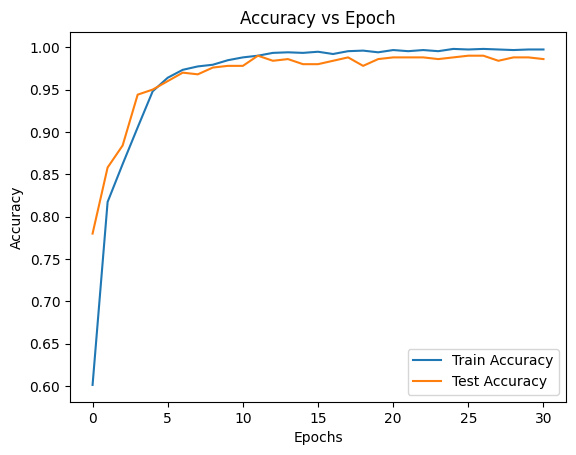

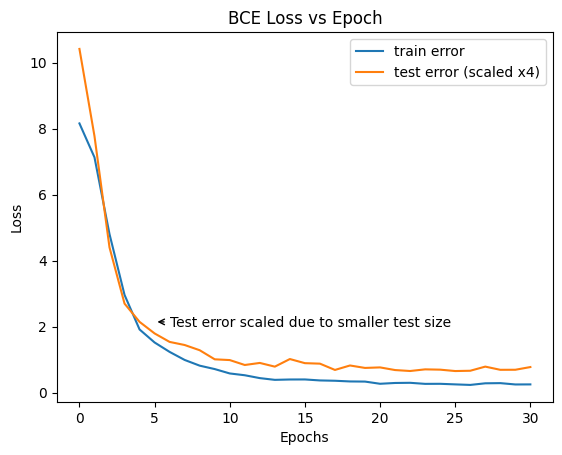

In [ ]:
# Plot accuracy and loss curves to observe training dynamics
import matplotlib.pyplot as plt 
import numpy as np

plt.figure(0)
plt.plot(epochs, train_acc_arr, label= "Train Accuracy")
plt.plot(epochs, test_acc_arr, label= "Test Accuracy")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.figure(1)
plt.plot(epochs, train_losses, label= "train error")
plt.plot(epochs, test_losses * 4, label= "test error (scaled x4)")  # scaled for visualization
plt.title("BCE Loss vs Epoch")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.annotate("Test error scaled due to smaller test size", 
    xy=(5, test_losses[4]*4), xytext=(6, 2),
    arrowprops=dict(facecolor='black', arrowstyle="->"))

The validation accuracy plateaus lower than train accuracy

The test error plateaus higher than train error, after adjusting for 4x sample size.

test error and test accuracy fluctuates much more than training error and accuracy respectively

Part A, Q2 (10 marks)
---

In this question, we will determine the optimal learning rate for the Adam optimizer. Find the optimal learning rate by training the neural network and evaluating the performances for different learning rates. Note: Use 5-fold cross-validation on training partition to perform hyperparameter selection. You will have to reconsider the scaling of the dataset during the 5-fold cross validation.

To reduce repeated code, you may need to place the network (MLP defined in QA1) in a separate file called **common_utils.py**. Import it here for Q2. You will not be repenalised for any error in QA1 here as the code in QA1 will not be remarked. The following code cell will not be marked.

In [ ]:
import common_utils

>Plot mean cross-validation accuracies and mean cross-validation AUC scores on the final epoch for different learning rates as scatter plots. Limit search space to learning rates {0.0001, 0.0005, 0.001, 0.005, 0.01}. Keep batch_size fixed at 128. Create a table of time taken to train the network on the last epoch against different learning rates. Generate a confusion matrix for the optimal learning rate configuration. Finally, select the optimal learning rate and state a reason for your selection.

1. Define different folds for different learning rates to get a dictionary of training and validation datasets. Preprocess your datasets accordingly. Please use the following name conventions:
    - X_train_scaled_dict[learning_rate] is a list of the preprocessed training matrix for the different folds. 
    - X_val_scaled_dict[learning_rate] is a list of the processed validation matrix for the different folds. 
    - y_train_dict[learning_rate] and y_val_dict[learning_rate] is a list of labels for the different folds.

In [ ]:
lr_tuple = (0.0001, 0.0005, 0.001, 0.005, 0.01)
batch_size = 128

# may not use split_dataset, preprocess_dataset from common_utils due to them fixing the test and train datasets
from sklearn import preprocessing

label_encoder = preprocessing.LabelEncoder()
standard_scaler = preprocessing.StandardScaler()

df_cpy = df.copy()
df_cpy = df.sample(frac=1).reset_index(drop=True)
df_cpy['label'] = label_encoder.fit_transform(df_cpy['label'])
nd_X = df_cpy.drop(["filename", "label"], axis = 1).to_numpy()
nd_Y = df_cpy["label"].to_numpy().reshape(-1, 1)
nd_X = standard_scaler.fit_transform(nd_X)

dataloader_A2 = DataLoader(AudioDataset(nd_X,
    torch.tensor(nd_Y.reshape(-1, 1), dtype=torch.float32))
    , batch_size = 128)


from sklearn.model_selection import KFold

no_folds = 5
kf = KFold(n_splits=no_folds, shuffle=True, random_state=0)

X_train_scaled_dict = {}
X_val_scaled_dict = {}
y_train_dict = {}
y_val_dict = {}

for lr in lr_tuple:
    X_train_scaled_dict[lr], X_val_scaled_dict[lr] = [], []
    y_train_dict[lr], y_val_dict[lr] = [], []

    # Iterate once through kf.split
    for fold_idx, (train_idx, val_idx) in enumerate(kf.split(nd_X)):
        X_train_scaled_dict[lr].append(nd_X[train_idx])
        X_val_scaled_dict[lr].append(nd_X[val_idx])
        y_train_dict[lr].append(nd_Y[train_idx])
        y_val_dict[lr].append(nd_Y[val_idx])

for lr in lr_tuple:
    print(f"LR = {lr}")
    print(f"  Number of folds: {len(X_train_scaled_dict[lr])}")

    for fold_idx in range(len(X_train_scaled_dict[lr])):
        xtr, xval = X_train_scaled_dict[lr][fold_idx], X_val_scaled_dict[lr][fold_idx]
        ytr, yval = y_train_dict[lr][fold_idx], y_val_dict[lr][fold_idx]

        print(f"    Fold {fold_idx+1}:")
        print(f"      X_train: {xtr.shape}")
        print(f"      X_val:   {xval.shape}")
        print(f"      y_train: {ytr.shape}")
        print(f"      y_val:   {yval.shape}")

    print("-" * 50)

from typing import Iterator

def generate_dataloader(
    X_scaled_dict: dict,
    y_dict: dict,
    lr,
    drop_last: bool = False,
    batch_size: int = 128
) -> Iterator[DataLoader]:
    """
    Yields DataLoader objects for each fold in the given data dictionaries.

    Args:
        X_scaled_dict (dict): Dictionary of scaled feature arrays keyed by learning rate.
        y_dict (dict): Dictionary of target label arrays keyed by learning rate.
        lr: Key used to select the desired learning-rate subset.
        drop_last (bool, optional): Whether to drop the last incomplete batch. Defaults to False.
        batch_size (int, optional): Mini-batch size for each DataLoader. Defaults to 128.

    Yields:
        DataLoader: A DataLoader containing a fold’s training or testing data.
    """
    for fold_idx in range(len(X_scaled_dict[lr])):
        nd_x = X_scaled_dict[lr][fold_idx]
        nd_y = y_dict[lr][fold_idx]
        # shuffle = false very important. Shuffle only during the kfold step
        dataloader = DataLoader(
            AudioDataset(
                np.array(nd_x),
                torch.tensor(nd_y.reshape(-1, 1), dtype=torch.float32)
            ),
            batch_size=batch_size,
            drop_last=drop_last,
            shuffle=False
        )
        yield dataloader

def generate_train_test_dataloaders(
    X_train_scaled_dict: dict,
    y_train_dict: dict,
    X_val_scaled_dict: dict,
    y_val_dict: dict,
    lr,
    drop_last: bool = False,
    batch_size: int = 128
) -> Iterator[Tuple[DataLoader, DataLoader]]:
    """
    Generates paired train and validation DataLoader objects for each fold.

    This function calls `generate_dataloader()` twice — once for the training data
    and once for the validation data — and yields them as pairs for each fold.

    Args:
        X_train_scaled_dict (dict): Dictionary of scaled training feature arrays keyed by learning rate.
        y_train_dict (dict): Dictionary of training label arrays keyed by learning rate.
        X_val_scaled_dict (dict): Dictionary of scaled validation feature arrays keyed by learning rate.
        y_val_dict (dict): Dictionary of validation label arrays keyed by learning rate.
        lr (float): Key used to select which learning-rate subset to use from the dictionaries.
        drop_last (bool, optional): Whether to drop the last incomplete batch in each DataLoader. Defaults to False.
        batch_size (int, optional): Mini-batch size for both training and validation DataLoaders. Defaults to 128.

    Yields:
        Tuple[DataLoader, DataLoader]: 
            A pair of `(train_loader, val_loader)` for each fold.
    """
    train_loaders = generate_dataloader(
        X_train_scaled_dict, y_train_dict, lr, drop_last=drop_last, batch_size=batch_size
    )
    val_loaders = generate_dataloader(
        X_val_scaled_dict, y_val_dict, lr, drop_last=drop_last, batch_size=batch_size
    )

    for train_loader, val_loader in zip(train_loaders, val_loaders):
        yield train_loader, val_loader


LR = 0.0001
  Number of folds: 5
    Fold 1:
      X_train: (1600, 57)
      X_val:   (400, 57)
      y_train: (1600, 1)
      y_val:   (400, 1)
    Fold 2:
      X_train: (1600, 57)
      X_val:   (400, 57)
      y_train: (1600, 1)
      y_val:   (400, 1)
    Fold 3:
      X_train: (1600, 57)
      X_val:   (400, 57)
      y_train: (1600, 1)
      y_val:   (400, 1)
    Fold 4:
      X_train: (1600, 57)
      X_val:   (400, 57)
      y_train: (1600, 1)
      y_val:   (400, 1)
    Fold 5:
      X_train: (1600, 57)
      X_val:   (400, 57)
      y_train: (1600, 1)
      y_val:   (400, 1)
--------------------------------------------------
LR = 0.0005
  Number of folds: 5
    Fold 1:
      X_train: (1600, 57)
      X_val:   (400, 57)
      y_train: (1600, 1)
      y_val:   (400, 1)
    Fold 2:
      X_train: (1600, 57)
      X_val:   (400, 57)
      y_train: (1600, 1)
      y_val:   (400, 1)
    Fold 3:
      X_train: (1600, 57)
      X_val:   (400, 57)
      y_train: (1600, 1)
      y_val

2. Perform hyperparameter tuning for the different learning rates with 5-fold cross validation.

In [ ]:
from typing import Dict, Any
import numpy as np
import torch
import pandas as pd
from IPython.display import display

class ExperimentResults():
    """Container class for storing and managing training results across results_key(lr or first layer neurons) and folds."""

    def __init__(self) -> None:
        """Initialize an empty results dictionary.

        Structure:
            {
                results_key: {
                    fold_idx: {
                        "train_losses": np.ndarray,
                        "test_losses": np.ndarray,
                        "epochs": np.ndarray,
                        "train_acc_arr": np.ndarray,
                        "test_acc_arr": np.ndarray,
                        "train_pred_probs": torch.Tensor,
                        "test_pred_probs": torch.Tensor,
                        "time_elapsed": float
                    },
                    ...
                },
                ...
            }
        """
        self.results: Dict[float, Any] = {}

    def __getitem__(self, key):
        return self.results[key]

    def __setitem__(self, key, value):
        self.results[key] = value

    def __contains__(self, key):
        return key in self.results

    def keys(self):
        return self.results.keys()

    def items(self):
        return self.results.items()

    def values(self):
        return self.results.values()
    def add_result(
        self,
        results_key: float,
        fold_idx: int,
        train_losses: np.ndarray,
        test_losses: np.ndarray,
        epochs: np.ndarray,
        train_acc_arr: np.ndarray,
        test_acc_arr: np.ndarray,
        train_pred_probs: torch.Tensor,
        test_pred_probs: torch.Tensor,
        time_elapsed: float
    ) -> None:
        """Add the results for a specific results_key and fold."""
        if results_key not in self.results:
            self.results[results_key] = {}

        self.results[results_key][fold_idx] = {
            "train_losses": train_losses,
            "test_losses": test_losses,
            "epochs": epochs,
            "train_acc_arr": train_acc_arr,
            "test_acc_arr": test_acc_arr,
            "train_pred_probs": train_pred_probs,
            "test_pred_probs": test_pred_probs,
            "time_elapsed": time_elapsed
        }

    def summary(self) -> None:
        """Print a concise summary of the recorded results."""
        for results_key, folds in self.results.items():
            print(f"results key = {results_key}: {len(folds)} folds recorded")
            self.show_results(results_key)

    def show_results(self, results_key: float) -> None:
        """Display all fold results for a given results_key as a styled pandas DataFrame.

        Args:
            results_key: results_key whose fold results to display.

        Displays:
            A formatted HTML DataFrame with key statistics per fold.
        """
        sub_results = self[results_key]

        # Create rows for each fold with key stats
        data_for_df = []
        for fold_idx, res in sub_results.items():
            data_for_df.append({
                "Fold": fold_idx,
                "Epochs": len(res["epochs"]),
                "Final Train Loss": float(res["train_losses"][-1]) if len(res["train_losses"]) > 0 else np.nan,
                "Final Test Loss": float(res["test_losses"][-1]) if len(res["test_losses"]) > 0 else np.nan,
                "Final Train Acc": float(res["train_acc_arr"][-1]) if len(res["train_acc_arr"]) > 0 else np.nan,
                "Final Test Acc": float(res["test_acc_arr"][-1]) if len(res["test_acc_arr"]) > 0 else np.nan,
                "Best Test Acc": float(np.max(res["test_acc_arr"])) if len(res["test_acc_arr"]) > 0 else np.nan,
                "Best Epoch": int(np.argmax(res["test_acc_arr"])) if len(res["test_acc_arr"]) > 0 else np.nan,
            })

        df = pd.DataFrame(data_for_df).set_index("Fold")
        styled = (
            df.style
            .background_gradient(subset=["Final Test Acc", "Best Test Acc"], cmap="Greens")
            .format(precision=4)
            .set_caption(f"Results for Learning Rate = {results_key}")
        )

        display(styled)

    def get_concat_pred_probs(self, results_key: float, no_folds: int = no_folds) -> Tuple[torch.Tensor, torch.Tensor]:
        """Return concatenated train and test prediction probabilities across all folds for a given learning rate.

        Args:
            results_key: results key whose folds' predictions are to be concatenated.
            no_folds: number of folds in experiment

        Returns:
            (train_pred_probs, test_pred_probs): Tuple of concatenated tensors.

        Notes:
            - Concatenation is done in ascending order of fold_idx.
        """
        if results_key not in self.results:
            raise ValueError(f"No results found for learning rate {results_key}")

        results_key_results = self.results[results_key]
        train_pred_list = []
        test_pred_list = []

        for fold_idx in range(no_folds): 
            if fold_idx not in results_key_results:
                print("Results_key subresults: ", results_key_results)
                raise ValueError(f"Missing results for fold {fold_idx} at results_key={results_key}")
            fold_data = results_key_results[fold_idx]
            train_pred_list.append(fold_data["train_pred_probs"][:, -1])
            test_pred_list.append(fold_data["test_pred_probs"][:, -1])
        

        train_pred_probs = torch.cat(train_pred_list, dim=0)
        test_pred_probs = torch.cat(test_pred_list, dim=0)

        return train_pred_probs, test_pred_probs
    
    def calculate_auc_acc_score(self, 
        results_key: float,
        y_train_dict: Dict[float, Dict[int, np.ndarray]] = y_train_dict,
        y_val_dict: Dict[float, Dict[int, np.ndarray]] = y_val_dict,
        no_folds: int = no_folds,
        lr_to_extract_label_from_y_train_dict_y_val_dict : Optional[float] = None
        ) -> Tuple[float, float, np.ndarray, np.ndarray, np.ndarray, np.ndarray, float, float]:
        # method stub, will define later in corresponding question section
        raise NotImplementedError("Implemented in later subpart")

In [12]:
results = ExperimentResults()

for lr in lr_tuple:
    for fold_idx, (train_dataloader, val_dataloader) in enumerate(generate_train_test_dataloaders(X_train_scaled_dict, y_train_dict, X_val_scaled_dict, y_val_dict, lr)):
        print(f"training for lr = {lr}, fold {fold_idx + 1}")
        model, loss_fn, optimizer = setup(adam_init_lr = lr)
        train_losses, test_losses, epochs, train_acc_arr, test_acc_arr, train_pred_probs, test_pred_probs, time_elapsed = train_and_test(train_dataloader, val_dataloader, model, loss_fn, optimizer)
        results.add_result(
            lr, fold_idx,
            train_losses, test_losses, epochs,
            train_acc_arr, test_acc_arr,
            train_pred_probs, test_pred_probs,
            time_elapsed
        )

training for lr = 0.0001, fold 1
training for lr = 0.0001, fold 2
training for lr = 0.0001, fold 3
training for lr = 0.0001, fold 4
training for lr = 0.0001, fold 5
training for lr = 0.0005, fold 1
training for lr = 0.0005, fold 2
training for lr = 0.0005, fold 3
training for lr = 0.0005, fold 4
training for lr = 0.0005, fold 5
training for lr = 0.001, fold 1
training for lr = 0.001, fold 2
training for lr = 0.001, fold 3
training for lr = 0.001, fold 4
training for lr = 0.001, fold 5
training for lr = 0.005, fold 1
training for lr = 0.005, fold 2
training for lr = 0.005, fold 3
training for lr = 0.005, fold 4
training for lr = 0.005, fold 5
training for lr = 0.01, fold 1
training for lr = 0.01, fold 2
training for lr = 0.01, fold 3
training for lr = 0.01, fold 4
training for lr = 0.01, fold 5


In [13]:
results.summary()

results key = 0.0001: 5 folds recorded


,Epochs,Final Train Loss,Final Test Loss,Final Train Acc,Final Test Acc,Best Test Acc,Best Epoch
Fold,,,,,,,
0,83,0.4676,0.2157,0.9913,0.9880,0.9880,54
1,100,0.4074,0.2581,0.9940,0.9800,0.9820,96
2,100,0.4245,0.2792,0.9967,0.9820,0.9820,94
3,100,0.4003,0.1053,0.9947,0.9920,0.9920,58
4,100,0.3632,0.1775,0.9967,0.9900,0.9900,97


results key = 0.0005: 5 folds recorded


,Epochs,Final Train Loss,Final Test Loss,Final Train Acc,Final Test Acc,Best Test Acc,Best Epoch
Fold,,,,,,,
0,25,0.3534,0.2087,0.9960,0.9860,0.9880,16
1,60,0.2785,0.2120,0.9967,0.9880,0.9880,47
2,35,0.3109,0.2377,0.9973,0.9820,0.9820,34
3,38,0.2823,0.0867,0.9980,0.9940,0.9960,32
4,60,0.2620,0.1538,0.9987,0.9900,0.9900,22


results key = 0.001: 5 folds recorded


,Epochs,Final Train Loss,Final Test Loss,Final Train Acc,Final Test Acc,Best Test Acc,Best Epoch
Fold,,,,,,,
0,20,0.3172,0.2426,0.9967,0.9800,0.9880,17
1,24,0.2937,0.2178,0.9967,0.9840,0.9900,17
2,36,0.2952,0.2146,0.9960,0.9820,0.9840,28
3,19,0.3796,0.0944,0.9927,0.9940,0.9940,13
4,20,0.3195,0.1641,0.9973,0.9900,0.9920,14


results key = 0.005: 5 folds recorded


,Epochs,Final Train Loss,Final Test Loss,Final Train Acc,Final Test Acc,Best Test Acc,Best Epoch
Fold,,,,,,,
0,17,0.4251,0.3198,0.9920,0.9780,0.9860,15
1,20,0.4231,0.2874,0.9913,0.9820,0.9840,14
2,10,0.7056,0.3521,0.9873,0.9740,0.9780,4
3,10,0.7256,0.1482,0.9820,0.9900,0.9900,4
4,17,0.5185,0.1856,0.9907,0.9880,0.9920,11


results key = 0.01: 5 folds recorded


,Epochs,Final Train Loss,Final Test Loss,Final Train Acc,Final Test Acc,Best Test Acc,Best Epoch
Fold,,,,,,,
0,20,0.9516,0.6489,0.9760,0.9720,0.9840,14
1,23,0.8869,0.3012,0.9747,0.9760,0.9860,18
2,14,0.8283,0.4552,0.9820,0.9620,0.9760,8
3,17,0.8003,0.2094,0.9820,0.9860,0.9920,11
4,10,0.8712,0.2351,0.9780,0.9880,0.9880,9


3. Plot scatterplot of mean cross validation accuracies and AUC scores on the final epoch for the different learning rates. Limit search space to learning rates {0.0001, 0.0005, 0.001, 0.005, 0.01}.

In [ ]:
def combine_fold_targets(
        lr: float,
        y_train_dict: Dict[float, Dict[int, np.ndarray]] = y_train_dict,
        y_val_dict: Dict[float, Dict[int, np.ndarray]] = y_val_dict,
        no_folds: int = no_folds
    ) -> Tuple[np.ndarray, np.ndarray]:
    """
    Combine training and validation target arrays across multiple folds for a given learning rate.

    This function retrieves the per-fold target arrays for the specified learning rate
    from the provided training and validation dictionaries, and concatenates them into
    single NumPy arrays representing all folds combined.

    Args:
        lr (float): 
            The learning rate key identifying which set of targets to combine.
        y_train_dict (dict[float, dict[int, np.ndarray]], optional): 
            A nested dictionary mapping learning rates to per-fold training target arrays.
            Defaults to the global variable `y_train_dict`.
        y_val_dict (dict[float, dict[int, np.ndarray]], optional): 
            A nested dictionary mapping learning rates to per-fold validation target arrays.
            Defaults to the global variable `y_val_dict`.
        no_folds (int, optional): 
            The total number of folds to combine. 
            Defaults to the global variable `no_folds`.

    Returns:
        tuple[np.ndarray, np.ndarray]: 
            A tuple `(nd_train_target_labels, nd_val_target_labels)` where:
            - `nd_train_target_labels`: concatenated training target arrays across all folds.
            - `nd_val_target_labels`: concatenated validation target arrays across all folds.
    Notes:
        relies on generate_dataloader being false. I have no idea how dataloader discards the final few values
    """
    nd_train_target_labels = []
    nd_val_target_labels = []

    for fold_idx in range(no_folds):
        nd_train_target_label = y_train_dict[lr][fold_idx]
        nd_val_target_label = y_val_dict[lr][fold_idx]
        nd_train_target_labels.append(nd_train_target_label)
        nd_val_target_labels.append(nd_val_target_label)

    nd_train_target_labels = np.concatenate(nd_train_target_labels)
    nd_val_target_labels = np.concatenate(nd_val_target_labels)

    return nd_train_target_labels, nd_val_target_labels

from sklearn.metrics import roc_auc_score, roc_curve, auc
from typing import Union
def calculate_auc_acc_score(self: ExperimentResults, 
    results_key: float,
    y_train_dict: Dict[float, Dict[int, np.ndarray]] = y_train_dict,
    y_val_dict: Dict[float, Dict[int, np.ndarray]] = y_val_dict,
    no_folds: int = no_folds,
    lr_to_extract_label_from_y_train_dict_y_val_dict : Optional[float] = None
    ) -> Tuple[float, float, np.ndarray, np.ndarray, np.ndarray, np.ndarray, float, float]:

    if results_key not in self.results:
        raise Exception(f"results_key {results_key} not found!")
    tensor_train_pred_probs, tensor_val_pred_probs = self.get_concat_pred_probs(results_key, no_folds= no_folds)
    nd_train_pred_probs, nd_val_pred_probs = tensor_train_pred_probs.detach().numpy(), tensor_val_pred_probs.detach().numpy()

    # if results key is lr 
    if (results_key < 1):
        nd_train_target_labels, nd_val_target_labels = combine_fold_targets(results_key, y_train_dict, y_val_dict, no_folds)
    else:
        assert lr_to_extract_label_from_y_train_dict_y_val_dict is not None, "When results key is not learning rate, must provide separate learning to extract labels from y_train_dict and y_val_dicts"
        nd_train_target_labels, nd_val_target_labels = combine_fold_targets(lr_to_extract_label_from_y_train_dict_y_val_dict, y_train_dict, y_val_dict, no_folds)

    train_auc = roc_auc_score(nd_train_target_labels, nd_train_pred_probs)
    val_auc = roc_auc_score(nd_val_target_labels, nd_val_pred_probs)
    if lr not in self.results:
        self.results[results_key] = {}
    self.results[results_key]["train_auc"] = train_auc
    self.results[results_key]["val_auc"] = val_auc

    fpr_train, tpr_train, _thresholds_train = roc_curve(nd_train_target_labels, nd_train_pred_probs)
    fpr_val, tpr_val, _thresholds_val = roc_curve(nd_val_target_labels, nd_val_pred_probs)
    self.results[results_key]["fpr_train"] = fpr_train
    self.results[results_key]["tpr_train"] = tpr_train
    self.results[results_key]["fpr_val"] = fpr_val
    self.results[results_key]["tpr_val"] = tpr_val

    
    # overall accuracy not calculated via taking average of the different folds since the 128-batch limit may introduce weighting thats difficult to calculate
    # best to recalculate overall accuracy here
    nd_train_pred_labels, nd_val_pred_labels = (nd_train_pred_probs >= 0.5).astype(int), (nd_val_pred_probs >= 0.5).astype(int)
    train_acc, val_acc = np.mean(nd_train_pred_labels == nd_train_target_labels.ravel()).item(), np.mean(nd_val_pred_labels == nd_val_target_labels.ravel()).item()
    self.results[results_key]["train_acc"] = train_acc
    self.results[results_key]["val_acc"] = val_acc

    return float(train_auc), float(val_auc), fpr_train, tpr_train, fpr_val, tpr_val, train_acc, val_acc

ExperimentResults.calculate_auc_acc_score = calculate_auc_acc_score

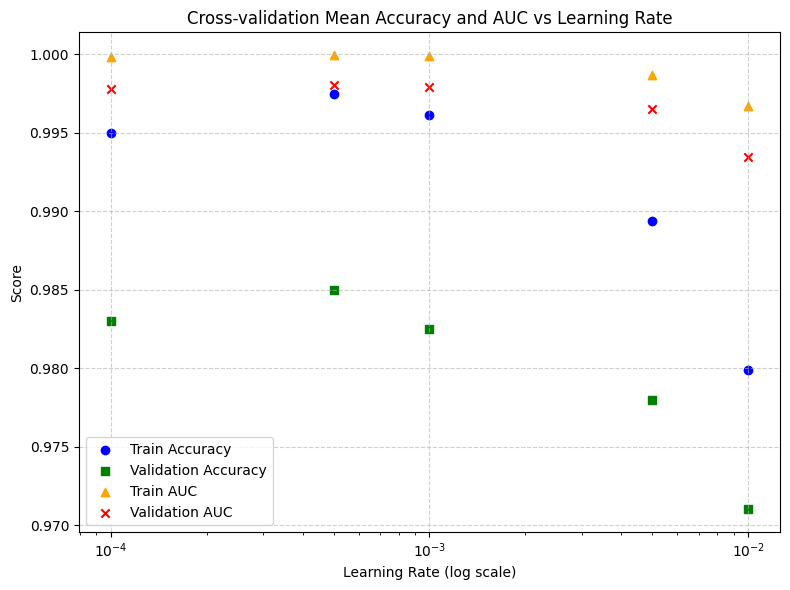

In [15]:
# Prepare containers
train_aucs, val_aucs = [], []
train_accs, val_accs = [], []

# Collect results
for lr in lr_tuple:
    train_auc, val_auc, fpr_train, tpr_train, fpr_val, tpr_val, train_acc, val_acc = results.calculate_auc_acc_score(lr)
    train_aucs.append(train_auc)
    val_aucs.append(val_auc)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

# Create the plot
plt.figure(figsize=(8, 6))
plt.title("Cross-validation Mean Accuracy and AUC vs Learning Rate")

# Scatter plots
plt.scatter(lr_tuple, train_accs, marker="o", color="blue", label="Train Accuracy")
plt.scatter(lr_tuple, val_accs, marker="s", color="green", label="Validation Accuracy")
plt.scatter(lr_tuple, train_aucs, marker="^", color="orange", label="Train AUC")
plt.scatter(lr_tuple, val_aucs, marker="x", color="red", label="Validation AUC")

# Log scale for LR since many orders of magnitude
plt.xscale("log")

# Labels and formatting
plt.xlabel("Learning Rate (log scale)")
plt.ylabel("Score")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


4. Create a table of time taken to train the network on the last epoch against different learning rates. Generate a confusion matrix for the optimal learning rate configuration.

C:\Users\kyeyo\AppData\Local\Temp\ipykernel_16640\3047729309.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


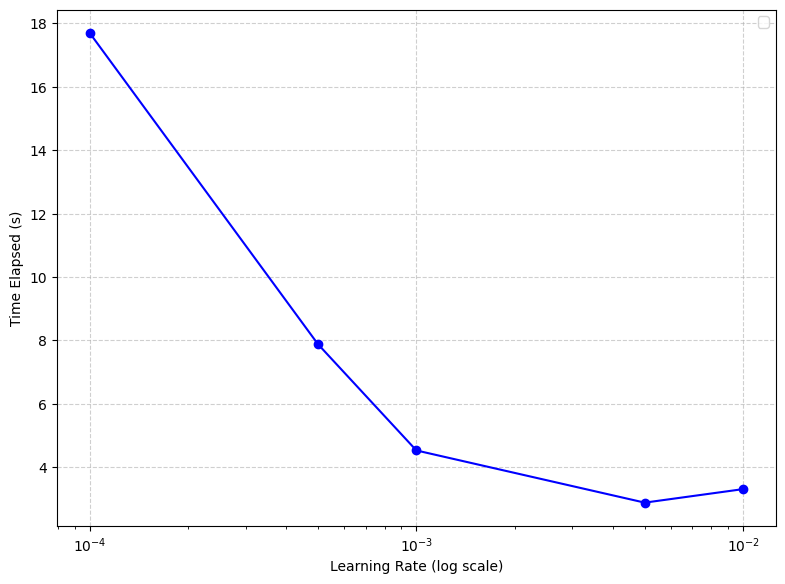

Validation accuracy: 0.985
Confusion matrix over all (test & validation) samples


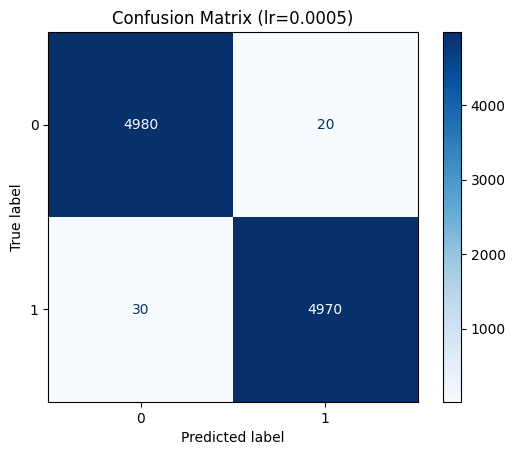

In [ ]:
time_arr = []

for lr in lr_tuple:
    total_time = 0
    for fold_idx in range(no_folds):
        total_time += results[lr][fold_idx]["time_elapsed"]
    results[lr]["time_elapsed"] = total_time
    time_arr.append(total_time)

# plot time elapsed against log rate
plt.figure(figsize=(8, 6))
plt.xscale("log")
plt.xlabel("Learning Rate (log scale)")
plt.ylabel("Time Elapsed (s)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.plot(lr_tuple, time_arr, marker="o", color="blue")
plt.show()

# based on the accuracy graph, it looks like this is the best 
optim_lr = 0.0005

t_train_pred_probs, t_val_pred_probs = results.get_concat_pred_probs(optim_lr)
nd_train_pred_labels, nd_val_pred_labels = ((t_train_pred_probs> 0.5).detach().numpy()).astype(int), ((t_val_pred_probs> 0.5).detach().numpy() > 0.5).astype(int)
nd_train_target_labels, nd_val_target_labels = combine_fold_targets(optim_lr)
nd_pred_labels, nd_target_labels = np.concatenate((nd_train_pred_labels, nd_val_pred_labels)), np.concatenate((nd_train_target_labels, nd_val_target_labels))

from sklearn.metrics import ConfusionMatrixDisplay

print(f"Validation accuracy: {results[optim_lr]["val_acc"]}")
print("Confusion matrix over all (test & validation) samples")
cm = confusion_matrix(nd_target_labels, nd_pred_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1])
disp.plot(cmap='Blues')
plt.title(f'Confusion Matrix (lr={optim_lr})')
plt.show()

5. Select the optimal learning rate and state a reason for your selection.

The best learning rate is 0.0005 due to the best validation accuracy and AUC out the the different learning rates. It still trains under 8 seconds which is good enough

Part A, Q3 (10 marks)
---
In this question, we will find the optimal number of hidden neurons for first hidden layer of the 5-layer network (4 hidden layers, output layer) designed in Q1 and Q2.

To reduce repeated code, you may need to import the network (MLP defined in QA1) from common_utils.py. You will not be repenalised for any error in QA1 here as the code in QA1 will not be remarked. The following code cell will not be marked.

In [17]:
# TODO: Enter your code here

# setup() is defined to work well for this question

> Plot the mean cross-validation accuracies on the final epoch for different numbers of first hidden-layer neurons using a scatter plot. Maintain the tapering pattern (e.g., if first layer is 256, use [256, 128, 64, 32]). Limit the search space of the first layer neurons to {64, 128, 256}. Continue using 5-fold cross validation on training dataset. Add ROC curve plotting for the final selected architecture.

1. Perform hyperparameter tuning for the different neurons with 5-fold cross validation.

In [ ]:
resultsQ3p1 = ExperimentResults()
# If use tuple not list, python thinks I'm writing literals instead of ints which break when matplotlib interact :<
neuron_list = [64, 128, 256]

for no_neuron in neuron_list:
    for fold_idx, (train_dataloader, val_dataloader) in enumerate(generate_train_test_dataloaders(X_train_scaled_dict, y_train_dict, X_val_scaled_dict, y_val_dict, optim_lr)):
        print(f"training for no_neuron = {no_neuron}, fold {fold_idx + 1}")
        model, loss_fn, optimizer = setup(first_layer_size=no_neuron, adam_init_lr=optim_lr)
        train_losses, test_losses, epochs, train_acc_arr, test_acc_arr, train_pred_probs, test_pred_probs, time_elapsed = train_and_test(train_dataloader, val_dataloader, model, loss_fn, optimizer)
        resultsQ3p1.add_result(
            no_neuron, fold_idx,
            train_losses, test_losses, epochs,
            train_acc_arr, test_acc_arr,
            train_pred_probs, test_pred_probs,
            time_elapsed
        )

training for no_neuron = 64, fold 1
training for no_neuron = 64, fold 2
training for no_neuron = 64, fold 3
training for no_neuron = 64, fold 4
training for no_neuron = 64, fold 5
training for no_neuron = 128, fold 1
training for no_neuron = 128, fold 2
training for no_neuron = 128, fold 3
training for no_neuron = 128, fold 4
training for no_neuron = 128, fold 5
training for no_neuron = 256, fold 1
training for no_neuron = 256, fold 2
training for no_neuron = 256, fold 3
training for no_neuron = 256, fold 4
training for no_neuron = 256, fold 5


2. Plot the mean cross-validation accuracies on the final epoch for different numbers of first hidden-layer neurons using a scatter plot. Limit the search space of the first layer neurons to {64, 128, 256}.

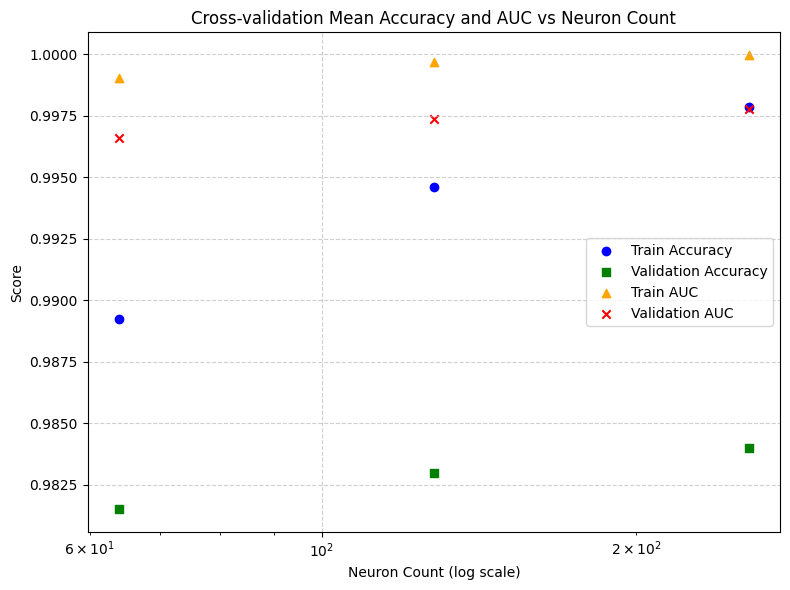

In [ ]:
# Prepare containers
train_aucs, val_aucs = [], []
train_accs, val_accs = [], []

# Collect results
for no_neuron in neuron_list:
    train_auc, val_auc, fpr_train, tpr_train, fpr_val, tpr_val, train_acc, val_acc = resultsQ3p1.calculate_auc_acc_score(no_neuron, lr_to_extract_label_from_y_train_dict_y_val_dict= optim_lr)
    train_aucs.append(train_auc)
    val_aucs.append(val_auc)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

# Create the plot
plt.figure(figsize=(8, 6))
plt.title("Cross-validation Mean Accuracy and AUC vs Neuron Count")

# Scatter plots
plt.scatter(neuron_list, train_accs, marker="o", color="blue", label="Train Accuracy")
plt.scatter(neuron_list, val_accs, marker="s", color="green", label="Validation Accuracy")
plt.scatter(neuron_list, train_aucs, marker="^", color="orange", label="Train AUC")
plt.scatter(neuron_list, val_aucs, marker="x", color="red", label="Validation AUC")

# Log scale for neurons since many orders of magnitude
plt.xscale("log")

# Labels and formatting
plt.xlabel("Neuron Count (log scale)")
plt.ylabel("Score")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


> Select the optimal number of neurons for the hidden layer. State the rationale for your selection.

In [20]:
# TODO: Enter your code here

# not sure what this code cell is used for; wrote my answers in the markdown cell below

The optimal number of neurons are 256. 256 neurons produces the highest Train AOC and Train accuracy as compared to other number of neurons

> Plot the train and test accuracies against training epochs with the optimal number of neurons using a line plot. Add ROC curve plotting for the final selected architecture.
Note: use this optimal number of neurons for the rest of the experiments.

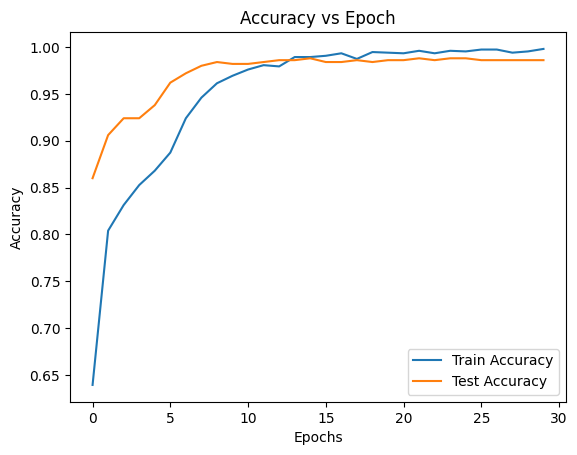

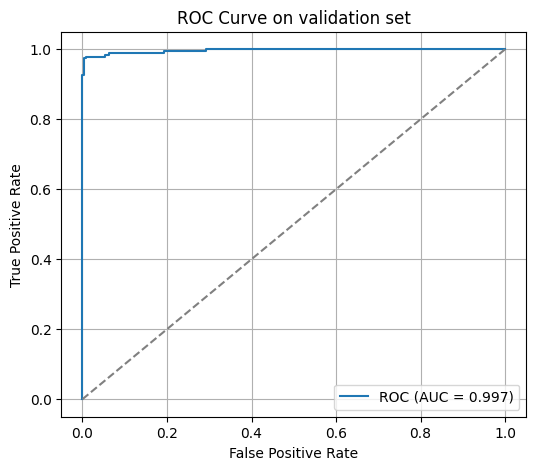

In [ ]:
resultsQ3p2 = ExperimentResults()

optim_neuron = 256

"""
Overall train/test acc easy to obtain, 
but train/test acc *history* hard to aggregate together: 
The number of epochs for each fold may be different 
Hence must retrain with optimal lr and neurons in this case
"""
# no need to fold anymore. Essentially just 80 : 20 train test split
fold_idx, no_folds = 0, 1
train_dataloader, val_dataloader = next(
    generate_train_test_dataloaders(
        X_train_scaled_dict, y_train_dict, X_val_scaled_dict, y_val_dict, optim_lr
    )
)

supermodel, loss_fn, optimizer = setup(first_layer_size=optim_neuron, adam_init_lr=optim_lr)
train_losses, test_losses, epochs, train_acc_arr, test_acc_arr, train_pred_probs, test_pred_probs, time_elapsed = train_and_test(train_dataloader, val_dataloader, supermodel, loss_fn, optimizer)
resultsQ3p2.add_result(
    optim_neuron, fold_idx,
    train_losses, test_losses, epochs,
    train_acc_arr, test_acc_arr,
    train_pred_probs, test_pred_probs,
    time_elapsed
)

train_auc, val_auc, fpr_train, tpr_train, fpr_val, tpr_val, train_acc, val_acc = resultsQ3p2.calculate_auc_acc_score(optim_neuron, no_folds=1, lr_to_extract_label_from_y_train_dict_y_val_dict= optim_lr)

plt.plot(epochs, train_acc_arr, label= "Train Accuracy")
plt.plot(epochs, test_acc_arr, label= "Test Accuracy")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

roc_auc = auc(fpr_val, tpr_val)
plt.figure(figsize=(6,5))
plt.plot(fpr_val, tpr_val, label=f'ROC (AUC = {roc_auc:.3f})')
plt.plot([0,1],[0,1],'--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curve on validation set')
plt.legend()
plt.grid(True)
plt.show()

Part A, Q4 (10 marks)
---
In this section, we will understand the utility of such a neural network for a test audio. 

Please use the 'audio_test.wav' as a test sample. Preprocess the data using the function 'extract_features' in common_utils.py. 
Do a model prediction on the sample test audio and obtain the predicted label using a threshold of 0.5. The model used is the optimized pretrained model using the selected optimal learning rate and optimal number of neurons. 
Find the most important features on the model prediction for the test sample using SHAP. Plot the local feature importance with a force plot and explain your observations. 
Identify the top 5 most influential features (both positive and negative) and explain why these features make sense for music genre classification (Refer to the documentation and these three useful references:
https://christophm.github.io/interpretable-ml-book/shap.html#examples-5, 
https://towardsdatascience.com/deep-learning-model-interpretation-using-shap-a21786e91d16,  
https://medium.com/mlearning-ai/shap-force-plots-for-classification-d30be430e195) 

Identify the top 5 most influential features (both positive and negative) and explain why these features make sense for music genre classification.


To reduce repeated code, you may need to import the network (MLP defined in QA1) from **common_utils.py**. You will not be repenalised for any error in QA1 here as the code in QA1 will not be remarked. The following code cell will not be marked.

In [22]:
# TODO: Enter your code here

# I'll continue using the "supermodel" trained in the last code cell

> Install and import shap

In [ ]:
import shap

> Preprocess 'audio_test.wav' in the folder 'audio' using the function 'extract_features' in common_utils.py. Use a pandas dataframe to store the features, using variable name 'df', and fill the size of 'df' in 'size_row' and 'size_column'.

In [24]:
from IPython.display import Audio
Audio("./audio_test.wav")

In [25]:
from sklearn.preprocessing import StandardScaler
def get_original_scaler() -> StandardScaler:
    standard_scaler = StandardScaler()
    # need to repeat the exact steps from part 1 to get the same scaler 
    _df = pd.read_csv(r".\audio_gtzan.csv")
    # Add class column
    _df['label'] = 0  # default to 0
    _df.loc[_df['filename'].str.startswith('metal'), 'label'] = 1
    df_train_unscaled, y_train, df_test_unscaled, y_test = split_dataset(_df, ["filename", "label"], int(len(_df)/4), 0)
    # Fit the scaler on training data 
    standard_scaler.fit(df_train_unscaled)
    return standard_scaler

In [ ]:
features = common_utils.extract_features(
        r".\audio_test.wav"
    )
features.drop(labels=["filename"], axis=1, inplace=True)
feature_names = features.columns
# ill use the above features and put it into the df required

# Convert to ndarray
nd_features = features.to_numpy().astype(np.float32)

# scaling; prof if you want 100% confidence just comment out the next line; i give up on figuring out whats wrong
nd_features = get_original_scaler().transform(nd_features)

# Convert to tensor
features_tensor = torch.tensor(nd_features, dtype=torch.float)

df = features
size_row = df.shape[0]
size_column = df.shape[1]
print(df.shape)

(1, 57)


c:\Users\kyeyo\venvs\jupyterVenv15Oct2024\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


> Do a model prediction on the sample test audio and obtain the predicted label using a threshold of 0.5. The model used is the optimized pretrained model using the selected optimal learning rate and optimal number of neurons. 

 1.  Preprocess to obtain the test data, save the test data as numpy array, print the shape of the test data.

In [ ]:
train_dataloader, val_dataloader = next(
    generate_train_test_dataloaders(
        X_train_scaled_dict, y_train_dict, X_val_scaled_dict, y_val_dict, optim_lr
    )
)
first_batch_input = next(iter(train_dataloader))[0]

print(first_batch_input.shape)

torch.Size([128, 57])


2. Do a model prediction on the sample test audio and obtain the predicted label using a threshold of 0.5. The model used is the optimized pretrained model using the selected optimal learning rate and optimal number of neurons. Note: Please define the variable of your final predicted label as 'pred_label'.

In [ ]:
# Get model prediction
supermodel.eval()
with torch.no_grad():
    pred_p = model(features_tensor)[0].item()
    if (pred_p < 0.5):
        pred_p = 1 - pred_p
        pred_label = "Blues"
    else:
        pred_label = "Metal"
supermodel.train()

print(f"Predicted label: {pred_label} (confidence: {pred_p:.4f})")

print(pred_label)

Predicted label: Blues (confidence: 0.9863)
Blues


\# TODO: \<Enter your answer here\>

Predicted label is Blues

> Find the most important features on the model prediction for your test sample using SHAP. Create an instance of the DeepSHAP which is called DeepExplainer using traianing dataset: https://shap-lrjball.readthedocs.io/en/latest/generated/shap.DeepExplainer.html.

Plot the local feature importance with a force plot and explain your observations.  (Refer to the documentation and these three useful references:
https://christophm.github.io/interpretable-ml-book/shap.html#examples-5, 
https://towardsdatascience.com/deep-learning-model-interpretation-using-shap-a21786e91d16,  
https://medium.com/mlearning-ai/shap-force-plots-for-classification-d30be430e195) 


Identify the top 5 most influential features (both positive and negative) and explain why these features make sense for music genre classification.



Top 5 influential features:
1. spectral_centroid_mean — SHAP value: -0.15329
2. mfcc3_mean — SHAP value: -0.14585
3. mfcc7_mean — SHAP value: 0.11359
4. mfcc1_mean — SHAP value: -0.10553
5. mfcc2_mean — SHAP value: -0.09675


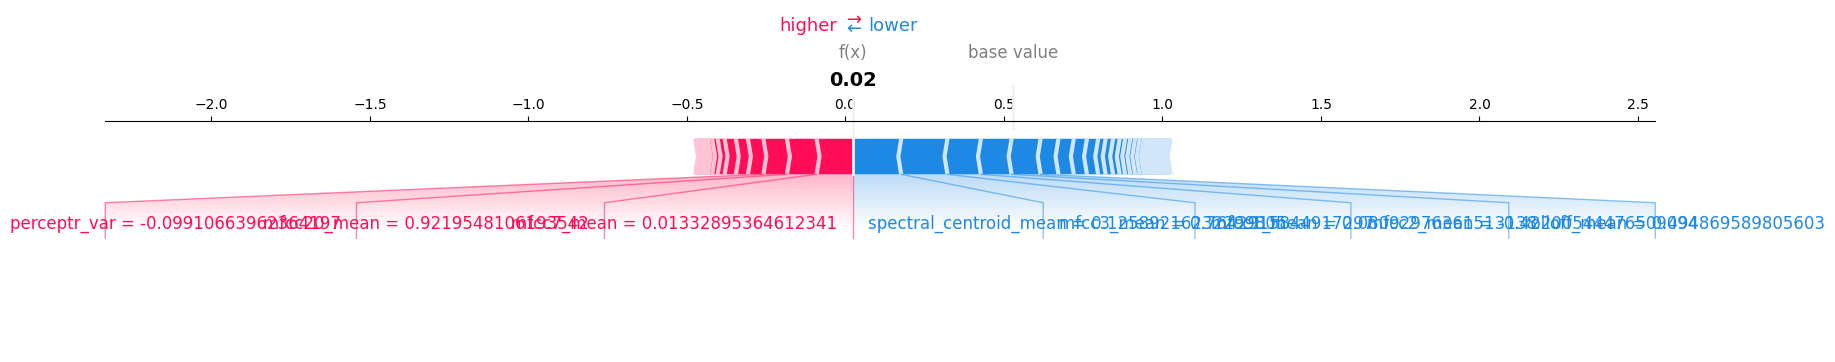

In [ ]:
'''
Fit the explainer on a subset of the data (you can try all but then gets slower)
Return approximate SHAP values for the model applied to the data given by X.
Plot the local feature importance with a force plot and explain your observations.
'''
# SHAP explanation
explainer = shap.DeepExplainer(supermodel, first_batch_input)
shap_values = explainer(features_tensor)
shap_array = np.squeeze(shap_values.values)

# Compute feature importances
feature_importance = np.abs(shap_array)
top5_indices = np.argsort(feature_importance)[-5:][::-1]
top5_names = [feature_names[i] for i in top5_indices]

# Display top features
print("\nTop 5 influential features:")
for i, idx in enumerate(top5_indices):
    print(f"{i+1}. {top5_names[i]} — SHAP value: {shap_array[idx]:.5f}")

shap.force_plot(
    explainer.expected_value.item(),
    shap_values.values[0].T,
    first_batch_input.detach().numpy()[0, :],
    feature_names = df.columns,
    matplotlib=True
)


<div style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, 'Helvetica Neue', Arial; max-width:800px; line-height:1.5;">
  <h2 style="margin-bottom:6px;">Model explanation — spectral & MFCC features</h2>

  <p>
    The model’s SHAP results indicate that <strong>blues (0)</strong> tends to have
    <strong>lower spectral centroid and lower MFCC 1–3 values</strong>, reflecting a warmer,
    smoother timbre with less high-frequency energy. In contrast, <strong>metal (1)</strong>
    is associated with higher values in higher-order MFCCs (mfcc7, mfcc20), which capture
    fine spectral texture, distortion and noise typical of electric guitars, cymbals,
    and dense mixes. Together these features let the model distinguish genres by
    <em>brightness, timbral complexity, and high-frequency detail</em>.
  </p>

  <h3 style="margin-bottom:6px;">Top 5 influential features (summary)</h3>
  <table style="border-collapse:collapse; width:100%; margin-bottom:12px;">
    <thead>
      <tr>
        <th style="text-align:left; padding:8px; border-bottom:2px solid #ddd;">Feature</th>
        <th style="text-align:left; padding:8px; border-bottom:2px solid #ddd;">SHAP value</th>
        <th style="text-align:left; padding:8px; border-bottom:2px solid #ddd;">Direction</th>
        <th style="text-align:left; padding:8px; border-bottom:2px solid #ddd;">Interpretation</th>
      </tr>
    </thead>
    <tbody>
      <tr>
        <td style="padding:8px; border-bottom:1px solid #f0f0f0;">spectral_centroid_mean</td>
        <td style="padding:8px; border-bottom:1px solid #f0f0f0;">-0.14713</td>
        <td style="padding:8px; border-bottom:1px solid #f0f0f0;">Negative → Blues (0)</td>
        <td style="padding:8px; border-bottom:1px solid #f0f0f0;">Lower brightness → warmer/blues timbre</td>
      </tr>
      <tr>
        <td style="padding:8px; border-bottom:1px solid #f0f0f0;">mfcc3_mean</td>
        <td style="padding:8px; border-bottom:1px solid #f0f0f0;">-0.13444</td>
        <td style="padding:8px; border-bottom:1px solid #f0f0f0;">Negative → Blues (0)</td>
        <td style="padding:8px; border-bottom:1px solid #f0f0f0;">Less mid–high emphasis → blues</td>
      </tr>
      <tr>
        <td style="padding:8px; border-bottom:1px solid #f0f0f0;">mfcc1_mean</td>
        <td style="padding:8px; border-bottom:1px solid #f0f0f0;">-0.11394</td>
        <td style="padding:8px; border-bottom:1px solid #f0f0f0;">Negative → Blues (0)</td>
        <td style="padding:8px; border-bottom:1px solid #f0f0f0;">Lower spectral slope/brightness → blues</td>
      </tr>
      <tr>
        <td style="padding:8px; border-bottom:1px solid #f0f0f0;">mfcc7_mean</td>
        <td style="padding:8px; border-bottom:1px solid #f0f0f0;">0.10972</td>
        <td style="padding:8px; border-bottom:1px solid #f0f0f0;">Positive → Metal (1)</td>
        <td style="padding:8px; border-bottom:1px solid #f0f0f0;">Finer timbral complexity → metal</td>
      </tr>
      <tr>
        <td style="padding:8px;">mfcc20_mean</td>
        <td style="padding:8px;">0.10014</td>
        <td style="padding:8px;">Positive → Metal (1)</td>
        <td style="padding:8px;">High-order spectral detail / noise → metal</td>
      </tr>
    </tbody>
  </table>

  <p style="font-size:0.95em; color:#555;">
    <strong>Quick note:</strong> negative SHAP values above indicate that lower values of that feature
    push the prediction toward <em>blues (0)</em>, while positive SHAP values push toward <em>metal (1)</em>.
  </p>

  <p style="font-size:0.95em; color:#555;">
    <strong>Quick note 2:</strong> I don't study music my Ringtone is Loonboon 😭
  </p>
</div>
